In [1]:
import pandas as pd
import numpy as np

# Gráficas
import matplotlib.pyplot as plt
import seaborn as sns

# Clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [13]:
df_calendar = pd.read_excel("DIM_CALENDAR (2).xlsx")
df_category = pd.read_csv("DIM_CATEGORY (2).csv")
df_sales = pd.read_csv("FACT_SALES (1).csv")
df_segment= pd.read_excel("DIM_SEGMENT (1).xlsx")
df_product= pd.read_excel("DIM_PRODUCT (1).xlsx")


print("CALENDAR")
display(df_calendar.head())

print("CATEGORY")
display(df_category.head())

print("SALES")
display(df_sales.head())

print("SEGMENT")
display(df_segment.head())

print("PRODUCT")
display(df_product.head())

CALENDAR


,WEEK,YEAR,MONTH,WEEK_NUMBER,DATE
0,01-21,2021,1,1,2021-01-10
1,02-21,2021,1,2,2021-01-17
2,03-21,2021,1,3,2021-01-24
3,04-21,2021,1,4,2021-01-31
4,05-21,2021,2,5,2021-02-07


CATEGORY


,ID_CATEGORY,CATEGORY
0,1,FABRIC TREATMENT and SANIT\r\n
1,2,AIR CARE
2,3,LAVAVAJILLAS
3,4,MEGA SUPERFICIES
4,5,LAVATORY CARE & BRC


SALES


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5


SEGMENT


,CATEGORY,ATTR1,ATTR2,ATTR3,FORMAT,SEGMENT
0,1,CLORO,CLORO,BAMBINO,LIQUIDO,BLEACH
1,1,CLORO,CLORO,GERMICIDA,LIQUIDO,BLEACH
2,1,CLORO,CLORO,MASCOTAS,LIQUIDO,BLEACH
3,1,CLORO,CLORO,MULTIUSOS,GEL,BLEACH
4,1,CLORO,CLORO,MULTIUSOS,LIQUIDO,BLEACH


PRODUCT


,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,INDS. ALEN,CLORALEX,0000075000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
1,INDS. ALEN,CLORALEX,0000075000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
2,INDS. ALEN,CLORALEX,0000075000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
3,INDS. ALEN,CLORALEX,0000075000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
4,INDS. ALEN,CLORALEX,0000075000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO


In [8]:
#Revisamos las variables de los archivos
print("Columnas de CALENDAR:")
print(df_calendar.columns)

print("\nColumnas de CATEGORY:")
print(df_category.columns)

print("\nColumnas de SALES:")
print(df_sales.columns)

print("\nColumnas de SEGMENT:")
print(df_segment.columns)

print("\nColumnas de PRODUCT:")
print(df_product.columns)

Columnas de CALENDAR:
Index(['WEEK', 'YEAR', 'MONTH', 'WEEK_NUMBER', 'DATE'], dtype='str')

Columnas de CATEGORY:
Index(['ID_CATEGORY', 'CATEGORY'], dtype='str')

Columnas de SALES:
Index(['WEEK', 'ITEM_CODE', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES',
       'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION'],
      dtype='str')

Columnas de SEGMENT:
Index(['CATEGORY', 'ATTR1', 'ATTR2', 'ATTR3', 'FORMAT', 'SEGMENT'], dtype='str')


In [14]:
#Revisa datos nullos
print("Nulos en CALENDAR:")
print(df_calendar.isnull().sum())

print("\nNulos en CATEGORY:")
print(df_category.isnull().sum())

print("\nNulos en SALES:")
print(df_sales.isnull().sum())

print("\nNulos en SEGMENT:")
print(df_segment.isnull().sum())

print("\nNulos en PRODUCT:")
print(df_product.isnull().sum())

Nulos en CALENDAR:
WEEK           0
YEAR           0
MONTH          0
WEEK_NUMBER    0
DATE           0
dtype: int64

Nulos en CATEGORY:
ID_CATEGORY    0
CATEGORY       0
dtype: int64

Nulos en SALES:
WEEK                           0
ITEM_CODE                      0
TOTAL_UNIT_SALES               0
TOTAL_VALUE_SALES              0
TOTAL_UNIT_AVG_WEEKLY_SALES    0
REGION                         0
dtype: int64

Nulos en SEGMENT:
CATEGORY    0
ATTR1       0
ATTR2       0
ATTR3       1
FORMAT      0
SEGMENT     0
dtype: int64

Nulos en PRODUCT:
MANUFACTURER        0
BRAND               0
ITEM                2
ITEM_DESCRIPTION    0
CATEGORY            0
FORMAT              0
ATTR1               6
ATTR2               0
ATTR3               6
dtype: int64


In [15]:
#  Identifica si hay duplicados de los DataFrames
print("DIM_CALENDAR")
print(df_calendar.duplicated().sum())

print("DIM_CATEGORY")
print(df_category.duplicated().sum())

print("DIM_SEGMENT")
print(df_segment.duplicated().sum())

print("FACT_SALES")
print(df_sales.duplicated().sum())

print("PRODUCT")
print(df_product.duplicated().sum())

DIM_CALENDAR
0
DIM_CATEGORY
0
DIM_SEGMENT
0
FACT_SALES
0
PRODUCT
0


In [17]:
#Unir los DataFrames relevantes:Realiza uniones entre los DataFrames para consolidar la información. 
df_union1 = df_sales.merge(df_product, left_on='ITEM_CODE', right_on='ITEM', how='left')
df_union1.head()

,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA


In [18]:
df_union2 = df_union1.merge(df_category,left_on='CATEGORY',right_on='ID_CATEGORY', how='left')
df_union2.head()

,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY_x,FORMAT,ATTR1,ATTR2,ATTR3,ID_CATEGORY,CATEGORY_y
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n


In [19]:
df_union3 = df_union2.merge( df_segment,
    left_on=['CATEGORY_x', 'ATTR1', 'ATTR2', 'ATTR3', 'FORMAT'],
    right_on=['CATEGORY', 'ATTR1', 'ATTR2', 'ATTR3', 'FORMAT'],
    how='left')
df_union3.head()

,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY_x,FORMAT,ATTR1,ATTR2,ATTR3,ID_CATEGORY,CATEGORY_y,CATEGORY,SEGMENT
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n,1,POWDER
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n,1,POWDER
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n,1,POWDER
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n,1,POWDER
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n,1,POWDER


In [20]:
df_union4 = df_union3.merge(df_calendar,on='WEEK',how='left')
df_union4.head()

,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,...,ATTR2,ATTR3,ID_CATEGORY,CATEGORY_y,CATEGORY,SEGMENT,YEAR,MONTH,WEEK_NUMBER,DATE
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n,1,POWDER,2022,8,34,2022-08-28
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n,1,POWDER,2022,8,34,2022-08-28
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n,1,POWDER,2022,8,34,2022-08-28
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n,1,POWDER,2022,8,34,2022-08-28
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT\r\n,1,POWDER,2022,8,34,2022-08-28


In [21]:
df_union4.isnull().sum()

WEEK                           0
ITEM_CODE                      0
TOTAL_UNIT_SALES               0
TOTAL_VALUE_SALES              0
TOTAL_UNIT_AVG_WEEKLY_SALES    0
REGION                         0
MANUFACTURER                   0
BRAND                          0
ITEM                           0
ITEM_DESCRIPTION               0
CATEGORY_x                     0
FORMAT                         0
ATTR1                          0
ATTR2                          0
ATTR3                          0
ID_CATEGORY                    0
CATEGORY_y                     0
CATEGORY                       0
SEGMENT                        0
YEAR                           0
MONTH                          0
WEEK_NUMBER                    0
DATE                           0
dtype: int64

In [22]:
#Limpiar los espacion inecesarios
for columna in df_union4.select_dtypes(include='str').columns:df_union4[columna] = df_union4[columna].str.strip()
df_union4.head()

,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,...,ATTR2,ATTR3,ID_CATEGORY,CATEGORY_y,CATEGORY,SEGMENT,YEAR,MONTH,WEEK_NUMBER,DATE
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28


In [23]:
#verificar como esta el dataframe
df_union4.columns.tolist()

['WEEK',
 'ITEM_CODE',
 'TOTAL_UNIT_SALES',
 'TOTAL_VALUE_SALES',
 'TOTAL_UNIT_AVG_WEEKLY_SALES',
 'REGION',
 'MANUFACTURER',
 'BRAND',
 'ITEM',
 'ITEM_DESCRIPTION',
 'CATEGORY_x',
 'FORMAT',
 'ATTR1',
 'ATTR2',
 'ATTR3',
 'ID_CATEGORY',
 'CATEGORY_y',
 'CATEGORY',
 'SEGMENT',
 'YEAR',
 'MONTH',
 'WEEK_NUMBER',
 'DATE']

In [58]:
#veriricar por ultima ves como quedo
df_union4.head()

,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,...,ATTR2,ATTR3,ID_CATEGORY,CATEGORY_y,CATEGORY,SEGMENT,YEAR,MONTH,WEEK_NUMBER,DATE
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28


In [97]:
# Ver las marcas que existen en la tabla final
print(df_union4['BRAND'].unique())

<ArrowStringArray>
[                   'VANISH',                     'SHOUT',
             'LA VALENCIANA',               'LOS PATITOS',
                 'OXI CLEAN',                  'CLARASOL',
                    'CLOROX',               'DR.BECKMANN',
                  'CLORALEX', 'CUELLOS PUNOS Y MANCHITAS',
                   'BANDERA',                 'BCLORHADA',
                  'PURO SOL',        'OTHERS MARCA UNIF.',
                      'TIDE',                     'LYSOL',
                 'BLANCATEL',                  'CLORALUZ',
                   'CLORTEX',                    'PATITO',
                   'SANYTOL',                    'IBERIA',
               'LA JAPONESA',                    'HARPIC']
Length: 24, dtype: str


In [98]:
# Filtrar únicamente los registros de la marca VANISH
df_vanish = df_union4[df_union4['BRAND'] == 'VANISH'].copy()
# Verificar que solamente tengamos VANISH
print(df_vanish['BRAND'].unique())
# Ver cuántos registros tenemos
print("Número de registros de Vanish:", len(df_vanish))

<ArrowStringArray>
['VANISH']
Length: 1, dtype: str
Número de registros de Vanish: 28377


In [99]:
# Mostrar las primeras filas
df_vanish.head()

,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,...,ATTR2,ATTR3,ID_CATEGORY,CATEGORY_y,CATEGORY,SEGMENT,YEAR,MONTH,WEEK_NUMBER,DATE
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,...,FABRIC TREATMENT,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28


In [100]:
# Revisar valores nulos
print("Valores nulos en Vanish:")
print(df_vanish.isnull().sum())

Valores nulos en Vanish:
WEEK                           0
ITEM_CODE                      0
TOTAL_UNIT_SALES               0
TOTAL_VALUE_SALES              0
TOTAL_UNIT_AVG_WEEKLY_SALES    0
REGION                         0
MANUFACTURER                   0
BRAND                          0
ITEM                           0
ITEM_DESCRIPTION               0
CATEGORY_x                     0
FORMAT                         0
ATTR1                          0
ATTR2                          0
ATTR3                          0
ID_CATEGORY                    0
CATEGORY_y                     0
CATEGORY                       0
SEGMENT                        0
YEAR                           0
MONTH                          0
WEEK_NUMBER                    0
DATE                           0
dtype: int64


In [101]:
# Variables que utilizaremos para formar los clusters
variables_clustering = ['TOTAL_UNIT_SALES',
                        'TOTAL_VALUE_SALES',
                        'TOTAL_UNIT_AVG_WEEKLY_SALES']
# Crear el DataFrame para el modelo
df_modelo = df_vanish[variables_clustering].copy()
df_modelo.head()

,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES
0,0.006,0.139,1.000
1,0.487,116.519,2.916
2,1.391,68.453,5.171
3,0.022,1.481,1.833
4,2.037,182.839,5.375


In [102]:
# Información de las variables
print("Inf. variables")
df_modelo.info()
# Estadísticas descriptivas
print("\nDescriptivas")
df_modelo.describe()

Inf. variables
<class 'pandas.DataFrame'>
Index: 28377 entries, 0 to 122001
Data columns (total 3 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   TOTAL_UNIT_SALES             28377 non-null  float64
 1   TOTAL_VALUE_SALES            28377 non-null  float64
 2   TOTAL_UNIT_AVG_WEEKLY_SALES  28377 non-null  float64
dtypes: float64(3)
memory usage: 886.8 KB

Descriptivas


,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES
count,28377.000000,28377.000000,28377.000000
mean,1.949922,76.410104,6.147886
std,5.242795,142.546133,7.386478
min,0.000000,0.001000,0.100000
25%,0.045000,3.234000,2.134000
50%,0.372000,28.580000,3.171000
75%,1.517000,81.170000,6.405000
max,69.908000,1624.247000,79.510000


In [103]:
#Estandarizar con StandardScaler
from sklearn.preprocessing import StandardScaler
# Crear el escalador
scaler = StandardScaler()
# Estandarizar las variables
X_scaled = scaler.fit_transform(df_modelo)
# Convertir nuevamente a DataFrame
df_modelo_scaled = pd.DataFrame(X_scaled, columns=variables_clustering)
# Mostrar los datos estandarizados
df_modelo_scaled.head()

,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES
0,-0.370786,-0.535072,-0.696946
1,-0.279040,0.281380,-0.437549
2,-0.106610,-0.055822,-0.132256
3,-0.367734,-0.525657,-0.584170
4,0.016609,0.746641,-0.104637


In [104]:
# Comprobar media y desviación estándar
print("Media:")
print(df_modelo_scaled.mean())
print("\nDesviación estándar:")
print(df_modelo_scaled.std())

Media:
TOTAL_UNIT_SALES              -1.001576e-17
TOTAL_VALUE_SALES              8.012604e-18
TOTAL_UNIT_AVG_WEEKLY_SALES    2.804412e-17
dtype: float64

Desviación estándar:
TOTAL_UNIT_SALES               1.000018
TOTAL_VALUE_SALES              1.000018
TOTAL_UNIT_AVG_WEEKLY_SALES    1.000018
dtype: float64


In [105]:
#calculamos el número de clusters solamente para Vanish
from sklearn.cluster import KMeans
# Lista para guardar 
inercia = []
# Probar diferentes cantidades de clusters
for k in range(1, 11):
    kmeans = KMeans( n_clusters=k, random_state=42)
    kmeans.fit(df_modelo_scaled)
    # Guardar la inercia
    inercia.append(kmeans.inertia_)
inercia

[85131.00000000019,
 50130.6767620131,
 31304.432007433075,
 19456.74362193525,
 16355.357746699989,
 13059.440081192535,
 11279.044765159219,
 10696.487421629346,
 9292.576826412012,
 8183.950678290328]

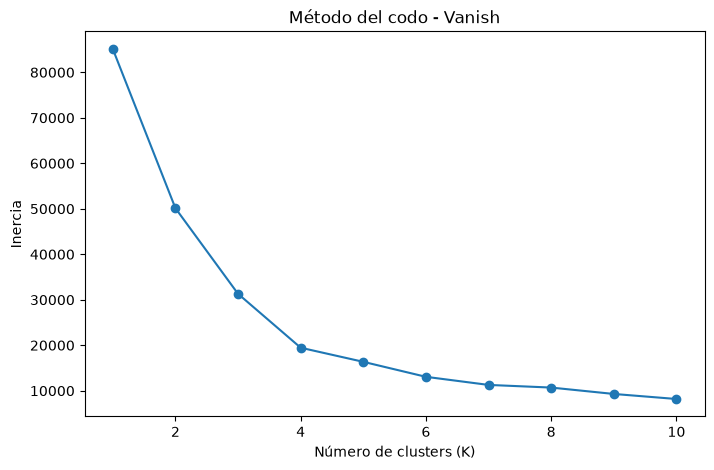

In [106]:
#graficamos
import matplotlib.pyplot as plt
K = range(1, 11)
plt.figure(figsize=(8, 5))
plt.plot(K, inercia, marker='o')
plt.title('Método del codo - Vanish')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.show()

In [107]:
#creamos los clusters
# Número de clusters seleccionado
k_optimo = 3
# Crear el modelo K-Means
kmeans = KMeans( n_clusters=k_optimo,random_state=42)
# Entrenar el modelo
kmeans.fit(df_modelo_scaled)
# Obtener el cluster asignado a cada registro
clusters = kmeans.labels_
# Mostrar los primeros resultados
print(clusters[:10])

[1 1 1 1 1 1 1 1 1 1]


In [108]:
#Relacionar cada ckuster con el registro
# Crear una copia de los datos de Vanish
df_resultado = df_vanish.copy()
# Agregar el cluster asignado por K-Means
df_resultado['CLUSTER'] = clusters
# Mostrar algunos resultados
df_resultado.head()

,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,...,ATTR3,ID_CATEGORY,CATEGORY_y,CATEGORY,SEGMENT,YEAR,MONTH,WEEK_NUMBER,DATE,CLUSTER
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,...,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28,1
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,...,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28,1
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,...,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28,1
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,...,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28,1
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,...,ROSA,1,FABRIC TREATMENT and SANIT,1,POWDER,2022,8,34,2022-08-28,1


In [109]:
# Vemos la cantidad de registros por cluster
cantidad_clusters = df_resultado['CLUSTER'].value_counts().sort_index()
print(cantidad_clusters)

CLUSTER
0     4385
1    23528
2      464
Name: count, dtype: int64


In [110]:
#Analizar el comportamiento de cada cluster
# Promedio de las variables de ventas por cluster
resumen_clusters = df_resultado.groupby('CLUSTER')[['TOTAL_UNIT_SALES',
                                                    'TOTAL_VALUE_SALES',
                                                    'TOTAL_UNIT_AVG_WEEKLY_SALES']].mean()
resumen_clusters

,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES
CLUSTER,,,
0,5.847678,170.215153,18.966043
1,0.591555,44.734686,3.506887
2,33.993043,796.074114,18.927655


In [111]:
# Relación entre región y cluster
tabla_region = pd.crosstab(df_resultado['REGION'],df_resultado['CLUSTER'])
tabla_region

CLUSTER,0,1,2
REGION,,,
TOTAL AUTOS AREA 1,483,3251,0
TOTAL AUTOS AREA 2,530,3791,0
TOTAL AUTOS AREA 3,529,3245,0
TOTAL AUTOS AREA 4,461,3481,0
TOTAL AUTOS AREA 5,860,3070,0
TOTAL AUTOS AREA 6,508,3417,0
TOTAL AUTOS SCANNING MEXICO,1014,3273,464


In [112]:
# Relación entre segmento y cluster
tabla_segmento = pd.crosstab(df_resultado['SEGMENT'], df_resultado['CLUSTER'])
tabla_segmento

CLUSTER,0,1,2
SEGMENT,,,
BAR,1937,982,160
LIQUID & GEL,1598,11140,285
POWDER,850,10286,19
PRETREAT,0,1120,0


In [113]:
# Relación entre categoría y cluster
tabla_categoria = pd.crosstab( df_resultado['CATEGORY'], df_resultado['CLUSTER'])
tabla_categoria

CLUSTER,0,1,2
CATEGORY,,,
1,4385,23528,464


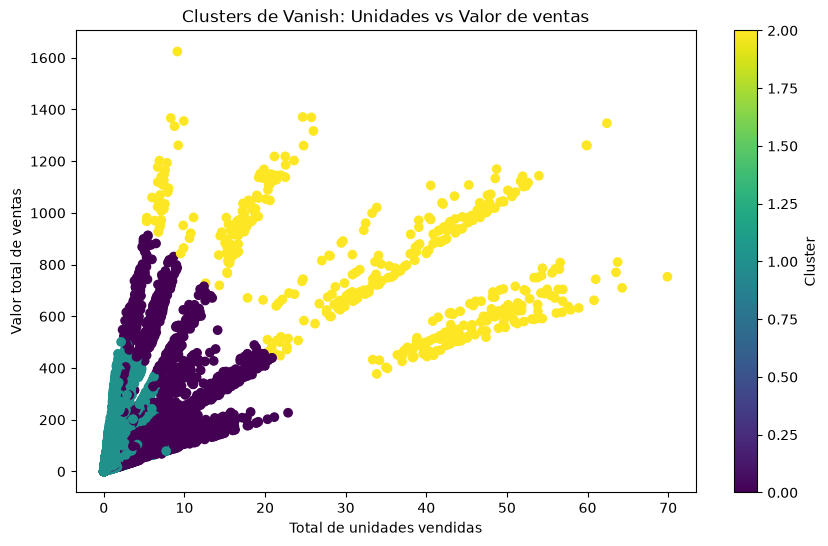

In [114]:
#Visualizar los cluster
plt.figure(figsize=(10, 6))
plt.scatter(df_resultado['TOTAL_UNIT_SALES'],
            df_resultado['TOTAL_VALUE_SALES'],
            c=df_resultado['CLUSTER'])
plt.title('Clusters de Vanish: Unidades vs Valor de ventas')
plt.xlabel('Total de unidades vendidas')
plt.ylabel('Valor total de ventas')
plt.colorbar(label='Cluster')
plt.show()

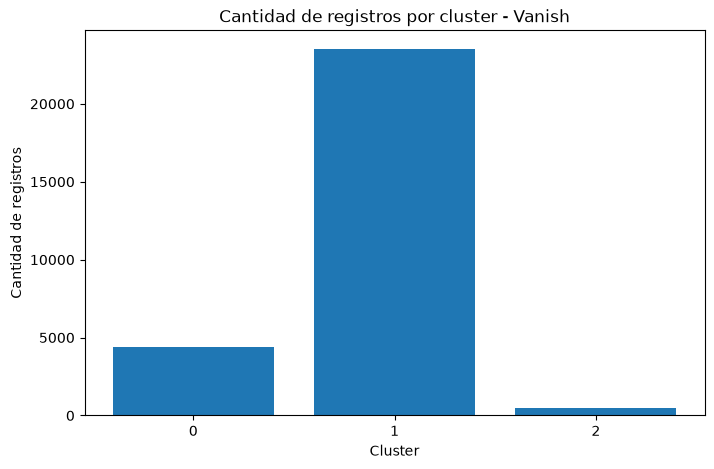

In [115]:
cantidad_clusters = df_resultado['CLUSTER'].value_counts().sort_index()
plt.figure(figsize=(8, 5))
plt.bar( cantidad_clusters.index.astype(str), cantidad_clusters.values)

plt.title('Cantidad de registros por cluster - Vanish')
plt.xlabel('Cluster')
plt.ylabel('Cantidad de registros')

plt.show()

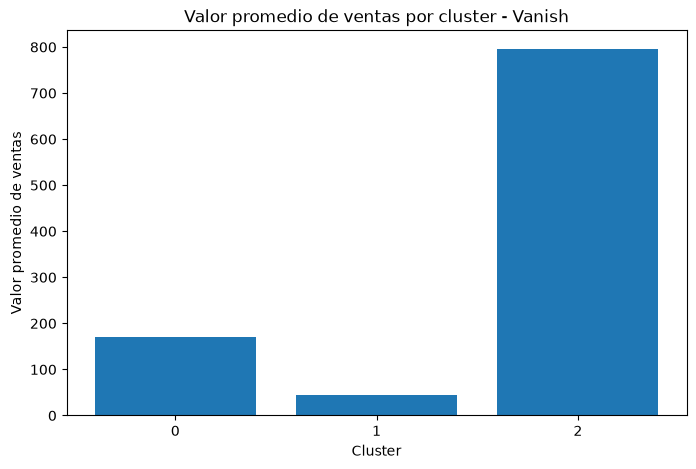

In [116]:
ventas_cluster = df_resultado.groupby('CLUSTER')['TOTAL_VALUE_SALES'].mean()
plt.figure(figsize=(8, 5))
plt.bar( ventas_cluster.index.astype(str),  ventas_cluster.values)
plt.title('Valor promedio de ventas por cluster - Vanish')
plt.xlabel('Cluster')
plt.ylabel('Valor promedio de ventas')
plt.show()

In [117]:
# Guardar los resultados del clustering de Vanish
df_resultado.to_csv('Resultados_Clustering_Vanish_EJ.csv', index=False)